# Lab 11: Attention — Completed Solution

**Tasks 1 and 2:** code, attention plots, highest-weight words, and written observations.

Run the cells from top to bottom. In Colab, upload `Lab_11_QnA_Dataset.csv` when prompted. No TensorFlow installation is needed; preprocessing uses Python and PyTorch.

The original lab is an **answer classifier with attention pooling**, rather than a full encoder–decoder that generates answers token by token. Each question is assigned to one of 12 answer groups.

### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
from pathlib import Path
from collections import Counter
import string
import random
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)  # Efficient for this small CPU exercise.
print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu


## Step 2 — Upload the dataset

In [2]:
# Accept the attached filename and the filename used in the starter notebook.
candidates = [Path(name) for name in (
    "Lab_11_QnA_Dataset.csv", "Lab_11_QnA_Dataset_Download.csv",
    "/content/Lab_11_QnA_Dataset.csv", "/content/Lab_11_QnA_Dataset_Download.csv",
    "upload/Lab_11_QnA_Dataset.csv"
)]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Place Lab_11_QnA_Dataset.csv beside this notebook.")
    uploaded = files.upload()
    dataset_path = next((Path(name) for name in uploaded if name.endswith(".csv")), None)
    if dataset_path is None:
        raise FileNotFoundError("Please upload the lab CSV dataset.")

df = pd.read_csv(dataset_path)
assert {"question", "answer_id", "answer"}.issubset(df.columns)
assert not df[["question", "answer_id", "answer"]].isna().any().any()
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
# Match the starter Tokenizer's lowercase/punctuation filtering.
# Apostrophes are retained, as in the default Keras Tokenizer.
filters = string.punctuation.replace("'", "") + "\t\n"
translation = str.maketrans({ch: " " for ch in filters})
def tokenize(text):
    return str(text).lower().translate(translation).split()

tokenized_questions = df["question"].map(tokenize).tolist()
assert all(tokenized_questions)
counts = Counter(word for words in tokenized_questions for word in words)
# Stable frequency order; zero is reserved for padding.
word_index = {word: i + 1 for i, (word, _) in enumerate(
    sorted(counts.items(), key=lambda item: item[1], reverse=True))}
max_length = max(map(len, tokenized_questions))
X = torch.zeros((len(df), max_length), dtype=torch.long)
for i, words in enumerate(tokenized_questions):
    X[i, :len(words)] = torch.tensor([word_index[w] for w in words])

# Map labels to consecutive class indices, as required by cross_entropy.
answer_ids = sorted(df["answer_id"].unique().tolist())
id_to_class = {answer_id: i for i, answer_id in enumerate(answer_ids)}
y = torch.tensor(df["answer_id"].map(id_to_class).to_numpy(), dtype=torch.long)
answer_lookup = df.drop_duplicates("answer_id").set_index("answer_id")["answer"].to_dict()
print("Vocabulary size:", len(word_index))
print("X shape:", tuple(X.shape), "| y shape:", tuple(y.shape))

Vocabulary size: 226
X shape: (168, 11) | y shape: (168,)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, len(answer_ids))

    def forward(self, x):
        mask = x.ne(0)  # True only at real words.
        hidden, _ = self.rnn(self.emb(x))  # (batch, words, 32)
        scores = self.att(hidden).squeeze(-1)  # (batch, words)
        scores = scores.masked_fill(~mask, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()
print(model)

RNN(
  (emb): Embedding(227, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


### Corrections to the starter code

1. `batch_first=True` makes the RNN read each question along its word dimension. Without it, this input layout incorrectly treats different questions as successive time steps [1].
2. `padding_idx=0` reserves the padding embedding [2]. Masking padding scores before softmax prevents padding from receiving attention.
3. `optimizer.zero_grad()` clears gradients each epoch instead of unintentionally accumulating them [3].
4. The plots use exactly the same tokens as preprocessing, so punctuation cannot misalign word labels and attention weights.

For each word position, the attention layer scores the RNN hidden state. Softmax converts those scores into weights that sum to 1. The weighted sum of hidden states is used to predict an answer group. A hidden state includes preceding context, so its weight is not an isolated measure of that word's meaning.

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_history = []
model.train()
for epoch in range(50):
    optimizer.zero_grad()  # Clear gradients before each backward pass.
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:2d}/50 | loss = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    logits, attention = model(X)
    accuracy = (logits.argmax(dim=1) == y).float().mean().item()
print(f"Training accuracy: {accuracy:.2%}")
print("This is training accuracy, not held-out test accuracy.")
# Verify attention normalization, padding exclusion, and batch independence.
assert torch.allclose(attention.sum(dim=1), torch.ones(len(df)), atol=1e-6)
assert torch.all(attention[X == 0] == 0)
with torch.no_grad():
    single_logits, single_attention = model(X[:1])
assert torch.allclose(logits[:1], single_logits, atol=1e-5)
assert torch.allclose(attention[:1], single_attention, atol=1e-5)
print("Checks passed: normalized attention, zero padding weights, independent questions.")

Epoch 10/50 | loss = 1.9305
Epoch 20/50 | loss = 1.2049
Epoch 30/50 | loss = 0.5520
Epoch 40/50 | loss = 0.1980
Epoch 50/50 | loss = 0.0688
Training accuracy: 98.81%
This is training accuracy, not held-out test accuracy.
Checks passed: normalized attention, zero padding weights, independent questions.


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

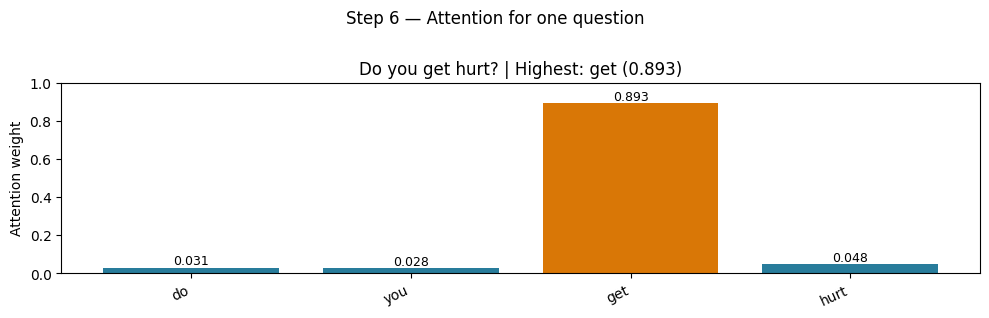

,row,question,highest_attention_word,weight,true_answer_id,predicted_answer_id,predicted_answer
0,0,Do you get hurt?,get,0.893149,0,0,I don't have a body.


In [6]:
def plot_attention(indices, title):
    """Plot real tokens and return their measured attention summaries."""
    model.eval()
    with torch.no_grad():
        logits, weights = model(X[indices])
    fig, axes = plt.subplots(len(indices), 1, figsize=(10, 3.2 * len(indices)), squeeze=False)
    rows = []
    for position, idx in enumerate(indices):
        words = tokenized_questions[idx]
        values = weights[position, :len(words)].cpu().numpy()
        top = int(values.argmax())
        predicted_id = answer_ids[int(logits[position].argmax())]
        ax = axes[position, 0]
        ax.bar(range(len(words)), values,
               color=["#d97706" if j == top else "#287c9b" for j in range(len(words))])
        ax.set_xticks(range(len(words)), words, rotation=25, ha="right")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Attention weight")
        ax.set_title(f'{df.loc[idx, "question"]} | Highest: {words[top]} ({values[top]:.3f})')
        for j, value in enumerate(values):
            ax.text(j, value + 0.015, f"{value:.3f}", ha="center", fontsize=9)
        rows.append({"row": idx, "question": df.loc[idx, "question"],
                     "highest_attention_word": words[top], "weight": float(values[top]),
                     "true_answer_id": df.loc[idx, "answer_id"],
                     "predicted_answer_id": predicted_id,
                     "predicted_answer": answer_lookup[predicted_id]})
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()
    return pd.DataFrame(rows)

# Original Step 6 example.
example_result = plot_attention([0], "Step 6 — Attention for one question")
display(example_result)

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

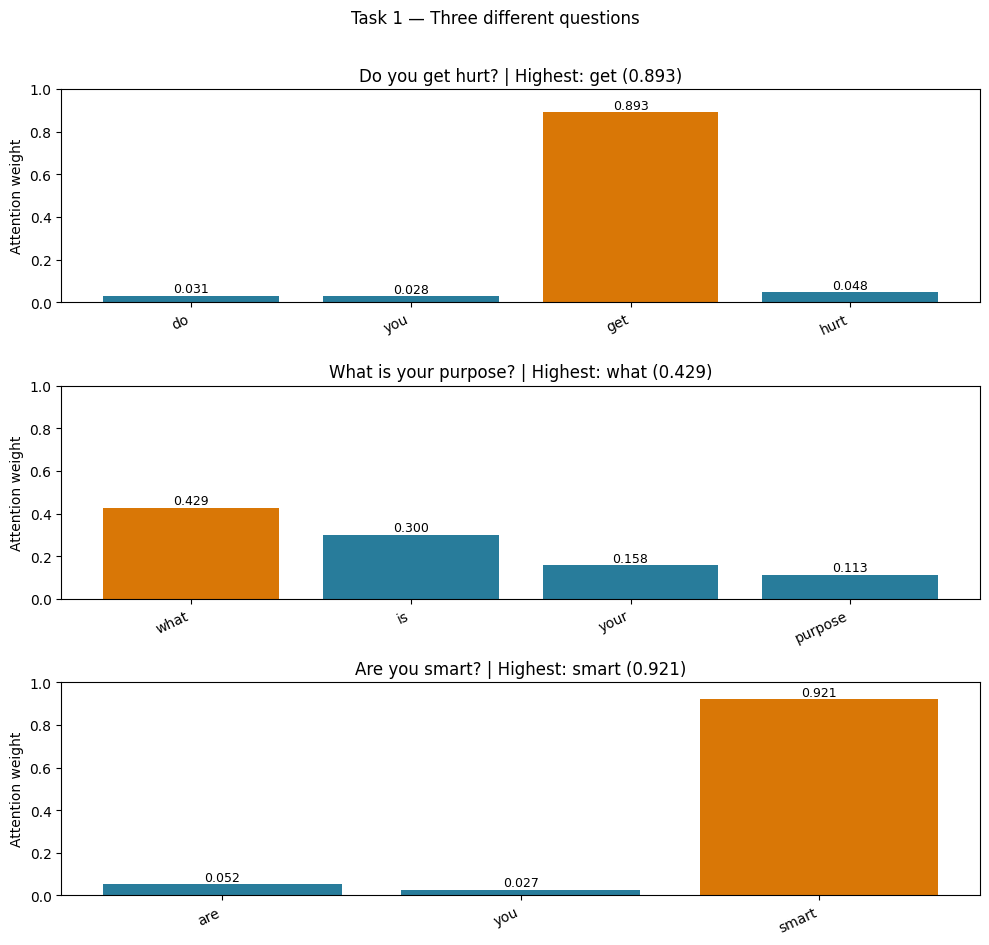

,row,question,highest_attention_word,weight,true_answer_id,predicted_answer_id,predicted_answer
0,0,Do you get hurt?,get,0.893149,0,0,I don't have a body.
1,70,What is your purpose?,what,0.428622,5,5,I'm here to answer your questions and help out.
2,154,Are you smart?,smart,0.920758,11,11,I do what I can.


In [7]:
# Task 1: three different questions from three answer groups.
selected_questions = ["Do you get hurt?", "What is your purpose?", "Are you smart?"]
task1_indices = [int(df.index[df["question"].eq(q)][0]) for q in selected_questions]
task1_results = plot_attention(task1_indices, "Task 1 — Three different questions")
display(task1_results)

### Task 1 — Written answer

The three charts above were produced by the trained model. Orange marks the highest-weight word.

| Question | Highest-weight word | Attention weight | Observation |
|---|---|---:|---|
| Do you get hurt? | get | 0.8931 | The model emphasizes a general verb instead of the more specific word “hurt.” |
| What is your purpose? | what | 0.4286 | The model emphasizes the question opener rather than “purpose,” the clearest topic word. |
| Are you smart? | smart | 0.9208 | This word directly identifies the topic of intelligence, so the focus matches human intuition. |

**Do the highest-weight words appear important?** Sometimes. “Smart” is clearly important for understanding the third question. However, “get” and “what” are less informative on their own than “hurt” and “purpose.” The weights are learned to help classify answer groups; they are not manually assigned semantic importance scores. A small training dataset can also encourage reliance on recurring wording patterns.

In this unidirectional RNN, the hidden state at a position represents that word and the words before it. The hidden state at “get” cannot include the later word “hurt,” and the hidden state at the first word “what” cannot include the later word “purpose.” These examples therefore show that learned attention need not match the words a person considers most meaningful. Attention weights alone do not establish a causal explanation [4]. All three selected questions were assigned to their correct answer groups in this run.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Both questions ask who created the chatbot.
Shared correct answer: People created me.


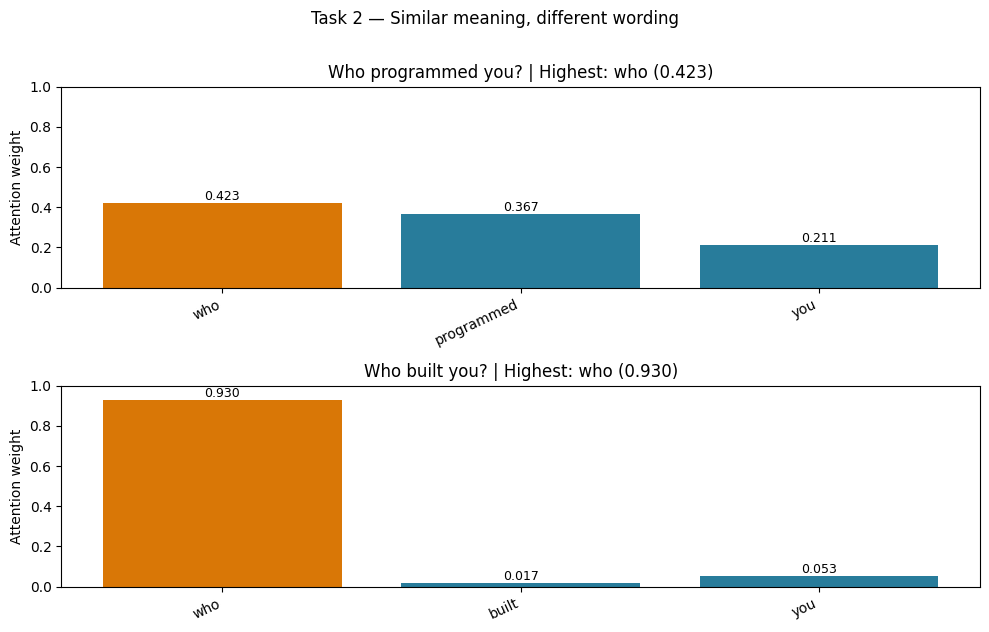

,row,question,highest_attention_word,weight,true_answer_id,predicted_answer_id,predicted_answer
0,42,Who programmed you?,who,0.422566,3,3,People created me.
1,46,Who built you?,who,0.929510,3,3,People created me.


In [8]:
# Task 2: a paraphrase pair about the chatbot's creator.
pair = ["Who programmed you?", "Who built you?"]
task2_indices = [int(df.index[df["question"].eq(q)][0]) for q in pair]
assert df.loc[task2_indices, "answer_id"].nunique() == 1
print("Both questions ask who created the chatbot.")
print("Shared correct answer:", df.loc[task2_indices[0], "answer"])
task2_results = plot_attention(task2_indices, "Task 2 — Similar meaning, different wording")
display(task2_results)

### Task 2 — Written answer

The selected questions are **“Who programmed you?”** and **“Who built you?”** Both ask who created the chatbot, and both have the correct answer **“People created me.”**

| Question | Highest-weight word | Attention weight | Predicted answer |
|---|---|---:|---|
| Who programmed you? | who | 0.4226 | People created me. |
| Who built you? | who | 0.9295 | People created me. |

**Does the model focus on similar or different words?** In this run, it focuses most on the same word, “who,” in both questions. This word is relevant because both questions ask about the identity of the creator. The weights differ: the first question distributes more attention across its other words, while the second concentrates most of its attention on “who.”

**What does this suggest?** Attention is a learned weighting of the hidden states for each input. Similar questions can share a focus, yet have different attention distributions because the other words change the scores and their softmax normalization. The architecture does not force paraphrases to have identical weights. This example is consistent with using a shared question pattern, but does not prove general understanding of paraphrases or performance on unseen questions.

**Run summary:** 50 epochs; final training loss 0.06885; training accuracy 98.81% (166/168 questions). No held-out evaluation was requested or performed, so this accuracy measures fit to the training data only. These observations describe the saved run; library versions or rerunning with different settings can change the weights.


## References

[1] [PyTorch: RNN, input shapes and batch_first](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html).

[2] [PyTorch: Embedding and padding_idx](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html).

[3] [PyTorch: Optimizer.zero_grad](https://docs.pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html).

[4] Jain, S. & Wallace, B. C. (2019). [Attention is not Explanation](https://aclanthology.org/N19-1357/), NAACL, 3543–3556. Attention weights should be interpreted cautiously rather than treated as definitive causal explanations.

The supplied `Lab_11_QnA_Dataset.csv` is the source of all questions, answer groups, and measured lab results.